# EDA: `hdi-ihdi-democracy-by-country.csv` (Kamalaksha)

This notebook looks at 2023 data for HDI, IHDI, and democracy scores by country.

I compare these scores to see how development and democracy are related. The charts show patterns in the data, but they do not prove that one causes the other.

I use `hdi-ihdi-democracy-by-country.csv` as the main dataset.

In [3]:
from pathlib import Path

import polars as pl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(160)

DATA = Path("..")          # the CSVs live in the repo root
FIGS = Path("figures")
FIGS.mkdir(exist_ok=True)

BLUE = "#2a78d6"
INK = "#0b0b0b"
MUTED = "#52514e"
GRAY = "#9a9893"
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRAY,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "text.color": INK,
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
})


def save(fig, name):
    fig.savefig(FIGS / f"kamalaksha_{name}.png", bbox_inches="tight", dpi=150)


hdi = pl.read_csv(DATA / "hdi-ihdi-democracy-by-country.csv")
hdi = hdi.with_columns(pl.col("IHDI").cast(pl.Float64, strict=False))
latest = hdi.filter(pl.col("Year") == 2023)

## 1. Profile

In [4]:
print("shape:", hdi.shape)
hdi.glimpse()

shape: (194, 8)
Rows: 194
Columns: 8
$ country_code             <str> 'CHE', 'NOR', 'ISL', 'HKG', 'DNK', 'SWE', 'DEU', 'IRL', 'SGP', 'AUS'
$ Rank                     <i64> 1, 2, 3, 4, 5, 5, 7, 7, 9, 10
$ HDI                      <f64> 0.967, 0.966, 0.959, 0.956, 0.952, 0.952, 0.95, 0.95, 0.949, 0.946
$ IHDI                     <f64> 0.891, 0.903, 0.91, 0.84, 0.898, 0.878, 0.881, 0.886, 0.825, 0.86
$ Country                  <str> 'Switzerland', 'Norway', 'Iceland', 'Hong Kong', 'Denmark', 'Sweden', 'Germany', 'Ireland', 'Singapore', 'Australia'
$ Year                     <i64> 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023
$ democracy_eiu            <f64> 9.14, 9.81, 9.45, 5.24, 9.28, 9.39, 8.8, 9.19, 6.18, 8.66
$ democracy_eiu_normalized <f64> 0.914, 0.9810000000000001, 0.945, 0.524, 0.9279999999999999, 0.9390000000000001, 0.8800000000000001, 0.9189999999999999, 0.618, 0.866



In [5]:
hdi.null_count()

country_code,Rank,HDI,IHDI,Country,Year,democracy_eiu,democracy_eiu_normalized
u32,u32,u32,u32,u32,u32,u32,u32
0,1,1,29,0,0,46,46


In [6]:
hdi.describe()

statistic,country_code,Rank,HDI,IHDI,Country,Year,democracy_eiu,democracy_eiu_normalized
str,str,f64,f64,f64,str,f64,f64,f64
"""count""","""194""",193.0,193.0,165.0,"""194""",194.0,148.0,148.0
"""null_count""","""0""",1.0,1.0,29.0,"""0""",0.0,46.0,46.0
"""mean""",null,96.854922,0.723741,0.589745,null,2023.0,5.686757,0.568676
"""std""",null,55.911665,0.155177,0.198451,null,0.0,2.152528,0.215253
"""min""","""AFG""",1.0,0.38,0.222,"""Afghanistan""",2023.0,2.12,0.212
"""25%""",null,49.0,0.602,0.399,null,2023.0,3.65,0.365
"""50%""",null,97.0,0.74,0.607,null,2023.0,6.0,0.6
"""75%""",null,145.0,0.847,0.75,null,2023.0,7.38,0.738
"""max""","""ZWE""",193.0,0.967,0.91,"""Zimbabwe""",2023.0,9.81,0.981


In [7]:
print("countries:", hdi["Country"].n_unique())
print("years:", hdi["Year"].unique().sort().to_list())
print("missing HDI:", hdi.filter(pl.col("HDI").is_null()).height)
print("missing IHDI:", hdi.filter(pl.col("IHDI").is_null()).height)
print("missing democracy score:", hdi.filter(pl.col("democracy_eiu").is_null()).height)

countries: 194
years: [2023]
missing HDI: 1
missing IHDI: 29
missing democracy score: 46


**What stands out:**

- The dataset has **194 rows and 8 columns**, covering **194 countries**.
- All rows are for **2023**.
- One country is missing HDI, 29 are missing IHDI, and 46 are missing a democracy score.
- The missing values mean that some charts use fewer than 194 countries.

I check for missing values and make sure the IHDI values can be read as numbers before comparing the data.

### 2a. Missing and non-numeric values

In [8]:
print("IHDI dtype:", hdi.schema["IHDI"])
print("non-numeric IHDI values:", hdi.filter(pl.col("IHDI").cast(pl.Float64, strict=False).is_null())["IHDI"].value_counts(sort=True).rows())
print("countries with missing IHDI:", hdi.filter(pl.col("IHDI").is_null())["Country"].to_list())
print("countries with missing democracy score:", hdi.filter(pl.col("democracy_eiu").is_null())["Country"].to_list())

IHDI dtype: Float64
non-numeric IHDI values: [(None, 29)]
countries with missing IHDI: ['Liechtenstein', 'Bahrain', 'Qatar', 'Saudi Arabia', 'San Marino', 'Kuwait', 'Saint Kitts and Nevis', 'Antigua and Barbuda', 'Trinidad and Tobago', 'Grenada', 'Saint Vincent and the Grenadines', 'Cuba', 'Libya', 'Turkmenistan', 'Guyana', 'Dominica', 'Uzbekistan', 'Lebanon', 'Belize', 'Nauru', 'Suriname', 'Equatorial Guinea', 'Micronesia (Federated States of)', 'Vanuatu', 'Solomon Islands', 'Syrian Arab Republic', 'Eritrea', 'Somalia', 'Taiwan']
countries with missing democracy score: ['Liechtenstein', 'Andorra', 'Saudi Arabia', 'San Marino', 'Saint Kitts and Nevis', 'Antigua and Barbuda', 'Brunei Darussalam', 'Bahamas', 'Barbados', 'Seychelles', 'Belarus', 'Palau', 'Grenada', 'Iran (Islamic Republic of)', 'Saint Vincent and the Grenadines', 'Maldives', 'Libya', 'Turkmenistan', 'Dominica', 'Tonga', 'Marshall Islands', 'Uzbekistan', 'Saint Lucia', 'Samoa', 'Belize', 'Nauru', 'Tajikistan', 'Tuvalu', 'E

The file has no IHDI value for 29 countries. These entries are read as missing values, so they are left out of calculations that need IHDI. Democracy scores are also missing for 46 countries.

### 2b. Quick checks on the main variables

In [9]:
print("HDI range:", latest["HDI"].min(), "to", latest["HDI"].max())
print("IHDI range:", latest["IHDI"].min(), "to", latest["IHDI"].max())
print("democracy range:", latest["democracy_eiu"].min(), "to", latest["democracy_eiu"].max())
print("highest HDI:", latest.sort("HDI", descending=True).select("Country", "HDI").head(5).rows())
print("lowest HDI:", latest.sort("HDI").select("Country", "HDI").head(5).rows())

HDI range: 0.38 to 0.967
IHDI range: 0.222 to 0.91
democracy range: 2.12 to 9.81
highest HDI: [('Taiwan', None), ('Switzerland', 0.967), ('Norway', 0.966), ('Iceland', 0.959), ('Hong Kong', 0.956)]
lowest HDI: [('Taiwan', None), ('Somalia', 0.38), ('South Sudan', 0.381), ('Central African Republic', 0.387), ('Chad', 0.394)]


### 2c. HDI and democracy relationship check

In [10]:
clean = latest.filter(pl.col("HDI").is_not_null() & pl.col("democracy_eiu").is_not_null())
print("rows used in the main analysis:", clean.height)
print("correlation HDI vs democracy:", clean.select(pl.corr("HDI", "democracy_eiu")).item())
print("correlation IHDI vs democracy:", clean.select(pl.corr("IHDI", "democracy_eiu")).item())

rows used in the main analysis: 147
correlation HDI vs democracy: 0.650891851933928
correlation IHDI vs democracy: 0.673640134363128


HDI, IHDI, and democracy scores are all in the same file, so I can compare them without joining other datasets. The plots use the 139 countries with all three values present.

These charts show HDI, IHDI, and democracy scores for the 139 countries with all three values available.

In [11]:
def summarize(s, label):
    print(f"{label}: n={s.len()}  mean={s.mean():.3f}  median={s.median():.3f}  sd={s.std():.3f}  "
          f"IQR={s.quantile(0.25):.3f} to {s.quantile(0.75):.3f}  min={s.min():.3f}  max={s.max():.3f}")


latest_clean = clean.drop_nulls(subset=["HDI", "IHDI", "democracy_eiu"])

### 3.1 Democracy score distribution

democracy score: n=139  mean=5.731  median=6.000  sd=2.143  IQR=4.140 to 7.640  min=2.120  max=9.810
lowest democracy scores: [('China', 2.12), ('Burundi', 2.13), ('Gabon', 2.18), ('Guinea', 2.21), ('Russia', 2.22)]
highest democracy scores: [('Norway', 9.81), ('New Zealand', 9.61), ('Iceland', 9.45), ('Sweden', 9.39), ('Finland', 9.3)]


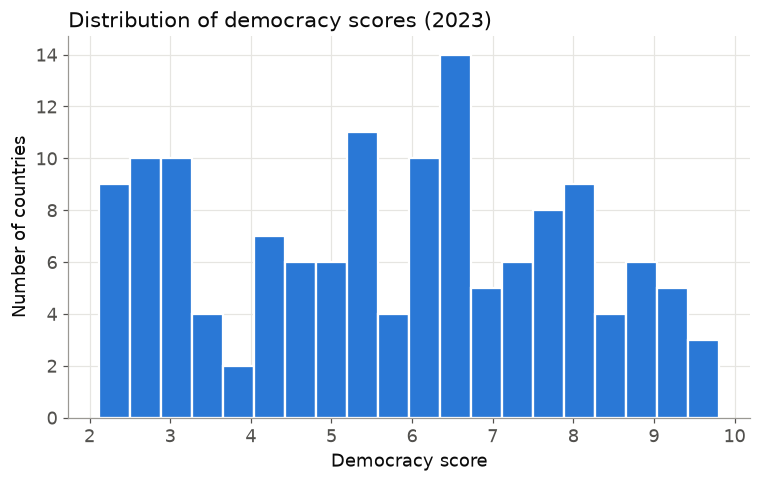

In [12]:
summarize(latest_clean["democracy_eiu"], "democracy score")
print("lowest democracy scores:", latest_clean.sort("democracy_eiu").select("Country", "democracy_eiu").head(5).rows())
print("highest democracy scores:", latest_clean.sort("democracy_eiu", descending=True).select("Country", "democracy_eiu").head(5).rows())

fig, ax = plt.subplots()
ax.hist(latest_clean["democracy_eiu"].to_list(), bins=20, color=BLUE, edgecolor="white", linewidth=1.5)
ax.set_xlabel("Democracy score")
ax.set_ylabel("Number of countries")
ax.set_title("Distribution of democracy scores (2023)", loc="left")
save(fig, "hdi_democracy_distribution")
plt.show()

Democracy scores range from **2.12 to 9.81**, with a middle value of **6.00**. The chart shows countries spread across much of the score range.

### 3.2 HDI and IHDI distribution

HDI: mean=0.735, median=0.758, min=0.394, max=0.967
IHDI: mean=0.603, median=0.627, min=0.261, max=0.910


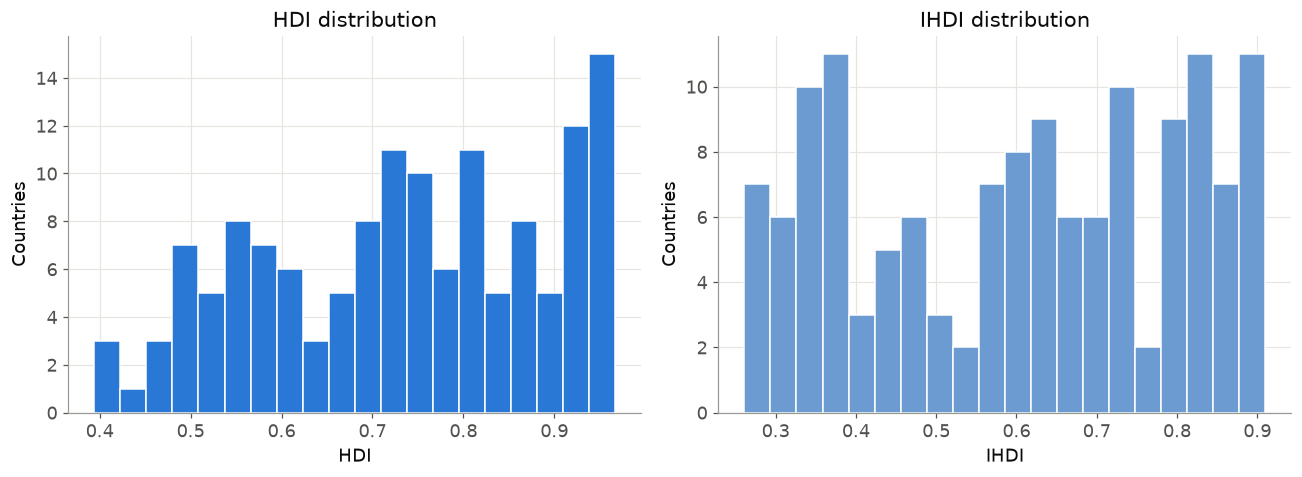

In [13]:
for label, col in [("HDI", "HDI"), ("IHDI", "IHDI")]:
    s = latest_clean[col]
    print(f"{label}: mean={s.mean():.3f}, median={s.median():.3f}, min={s.min():.3f}, max={s.max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(latest_clean["HDI"].to_list(), bins=20, color=BLUE, edgecolor="white")
axes[0].set_title("HDI distribution")
axes[0].set_xlabel("HDI")
axes[0].set_ylabel("Countries")
axes[1].hist(latest_clean["IHDI"].to_list(), bins=20, color="#6b9bd1", edgecolor="white")
axes[1].set_title("IHDI distribution")
axes[1].set_xlabel("IHDI")
axes[1].set_ylabel("Countries")
fig.tight_layout()
save(fig, "hdi_ihdi_distribution")
plt.show()

For these 139 countries, the middle HDI value is **0.758**, while the middle IHDI value is **0.627**. IHDI is lower because it also accounts for inequality.

### 3.3 Inequality loss

inequality loss summary:
inequality loss: n=139  mean=20.177  median=17.647  sd=11.520  IQR=9.535 to 31.204  min=4.752  max=43.003
highest inequality loss: [('Comoros', 43.003412969283275), ('Angola', 41.793570219966156), ('Mozambique', 41.43167028199566), ("Cote d'Ivoire", 40.44943820224719), ('Burkina Faso', 40.410958904109584)]
lowest inequality loss: [('Slovenia', 4.751619870410373), ('Iceland', 5.109489051094885), ('Czechia', 5.251396648044693), ('Slovakia', 5.4970760233918), ('Denmark', 5.672268907563016)]


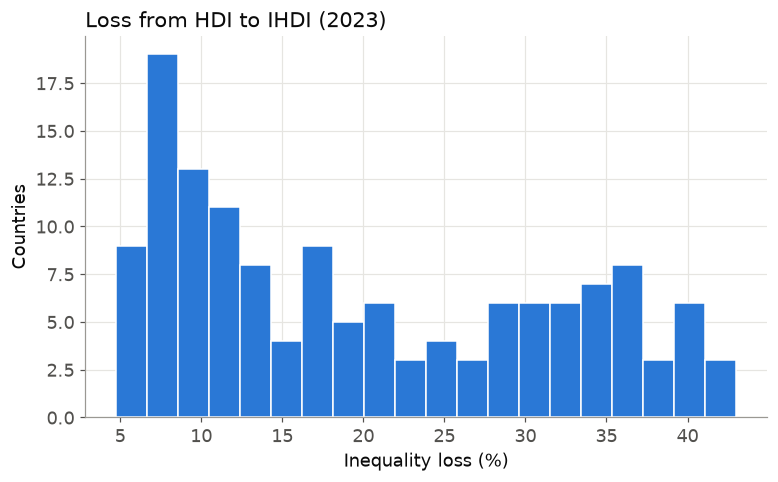

In [14]:
loss = latest_clean.with_columns(
    (100 * (1 - pl.col("IHDI") / pl.col("HDI"))).alias("inequality_loss")
)
print("inequality loss summary:")
summarize(loss["inequality_loss"], "inequality loss")
print("highest inequality loss:", loss.sort("inequality_loss", descending=True).select("Country", "inequality_loss").head(5).rows())
print("lowest inequality loss:", loss.sort("inequality_loss").select("Country", "inequality_loss").head(5).rows())

fig, ax = plt.subplots()
ax.hist(loss["inequality_loss"].to_list(), bins=20, color="#2a78d6", edgecolor="white")
ax.set_xlabel("Inequality loss (%)")
ax.set_ylabel("Countries")
ax.set_title("Loss from HDI to IHDI (2023)", loc="left")

save(fig, "hdi_inequality_loss")
plt.show()

For these countries, the middle loss from HDI to IHDI is about **17.6%**. The loss ranges from about **4.8% to 43.0%**, so the size of the gap differs a lot by country.

## 4. Relationships

This section checks how HDI, IHDI, and democracy are connected in the 2023 data.

### 4.1 Democracy score vs. HDI

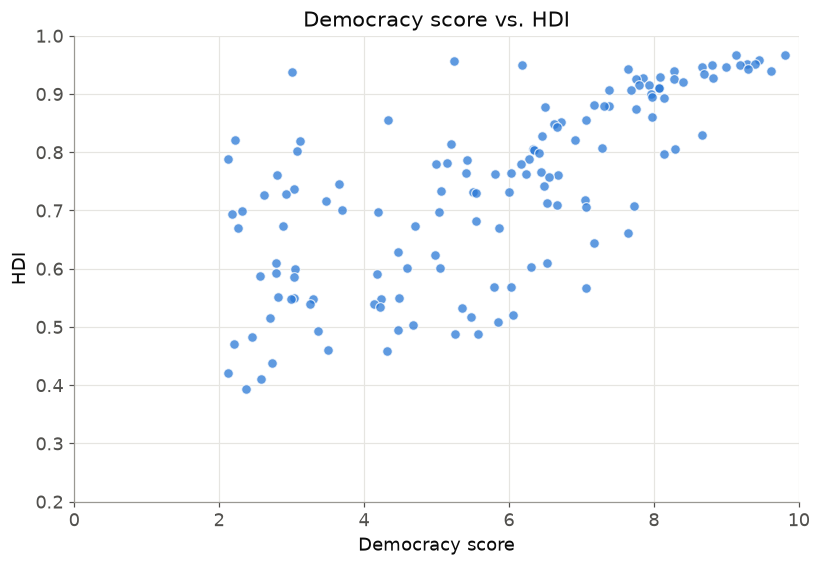

Pearson r between democracy and HDI: 0.697


In [15]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(latest_clean["democracy_eiu"].to_list(), latest_clean["HDI"].to_list(), s=40, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.8)
ax.set_xlabel("Democracy score")
ax.set_ylabel("HDI")
ax.set_title("Democracy score vs. HDI")
ax.set_xlim(0, 10)
ax.set_ylim(0.2, 1.0)
save(fig, "hdi_vs_democracy")
plt.show()

r = latest_clean.select(pl.corr("democracy_eiu", "HDI")).item()
print("Pearson r between democracy and HDI:", round(r, 3))

The chart shows a positive link between democracy scores and HDI. The correlation is **0.697**: countries with higher democracy scores often have higher HDI, but there are exceptions.

### 4.2 Democracy score vs. IHDI

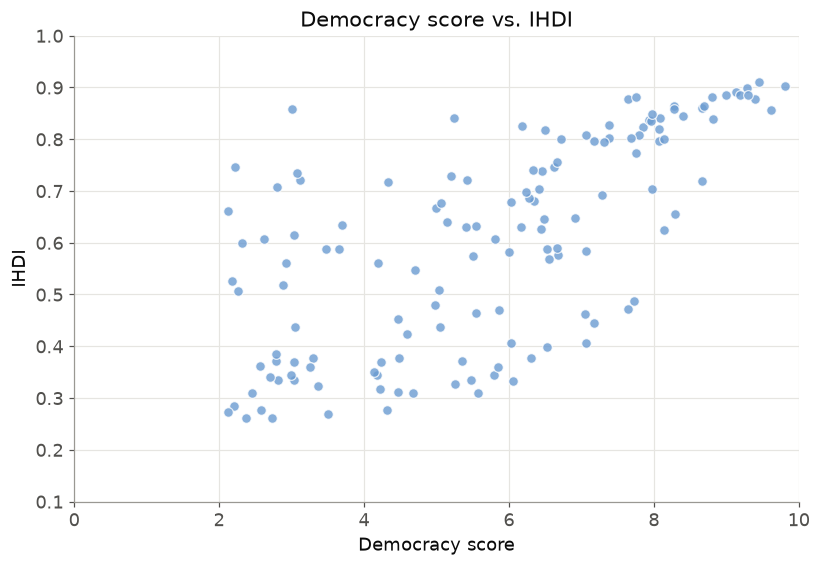

Pearson r between democracy and IHDI: 0.674


In [16]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(latest_clean["democracy_eiu"].to_list(), latest_clean["IHDI"].to_list(), s=40, color="#6b9bd1", alpha=0.8, edgecolor="white", linewidth=0.8)
ax.set_xlabel("Democracy score")
ax.set_ylabel("IHDI")
ax.set_title("Democracy score vs. IHDI")
ax.set_xlim(0, 10)
ax.set_ylim(0.1, 1.0)
save(fig, "ihdi_vs_democracy")
plt.show()

r_ihdi = latest_clean.select(pl.corr("democracy_eiu", "IHDI")).item()
print("Pearson r between democracy and IHDI:", round(r_ihdi, 3))

IHDI also tends to be higher where democracy scores are higher. The correlation is **0.674**, a positive link, though the countries do not all follow the same pattern.

### 4.3 HDI vs. IHDI

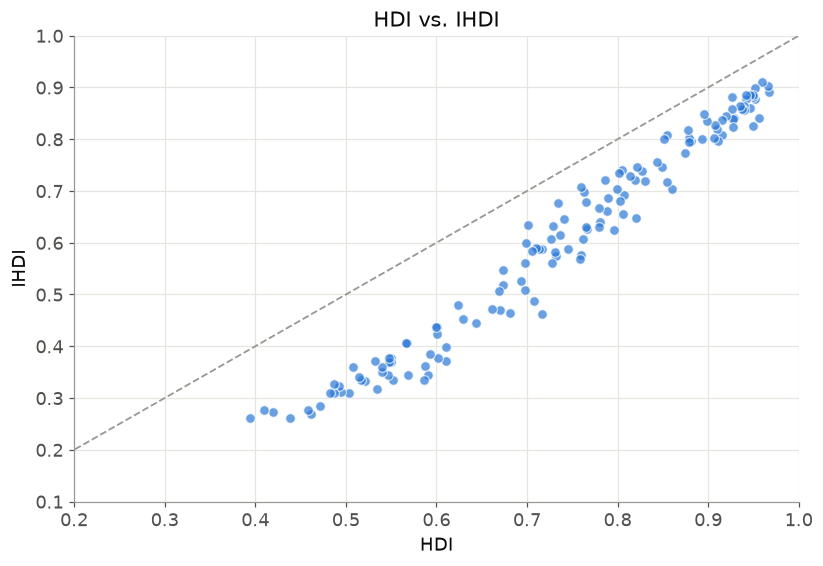

Pearson r between HDI and IHDI: 0.984


In [17]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(latest_clean["HDI"].to_list(), latest_clean["IHDI"].to_list(), s=40, color=BLUE, alpha=0.7, edgecolor="white", linewidth=0.8)
ax.plot([0, 1], [0, 1], linestyle="--", color=GRAY, linewidth=1.2)
ax.set_xlabel("HDI")
ax.set_ylabel("IHDI")
ax.set_title("HDI vs. IHDI")
ax.set_xlim(0.2, 1.0)
ax.set_ylim(0.1, 1.0)
save(fig, "hdi_vs_ihdi")
plt.show()

r_hdi_ihdi = latest_clean.select(pl.corr("HDI", "IHDI")).item()
print("Pearson r between HDI and IHDI:", round(r_hdi_ihdi, 3))

HDI and IHDI move closely together, with a correlation of **0.984**. Most points sit below the diagonal line, which means IHDI is lower than HDI for these countries.

### 4.4 Top countries by gap

In [18]:
with_gap = latest_clean.with_columns(
    (100 * (1 - pl.col("IHDI") / pl.col("HDI"))).alias("inequality_loss")
)
print("largest HDI-IHDI gaps:")
print(with_gap.sort("inequality_loss", descending=True).select("Country", "HDI", "IHDI", "inequality_loss").head(10).rows())

print("smallest HDI-IHDI gaps:")
print(with_gap.sort("inequality_loss").select("Country", "HDI", "IHDI", "inequality_loss").head(10).rows())

largest HDI-IHDI gaps:
[('Comoros', 0.586, 0.334, 43.003412969283275), ('Angola', 0.591, 0.344, 41.793570219966156), ('Mozambique', 0.461, 0.27, 41.43167028199566), ("Cote d'Ivoire", 0.534, 0.318, 40.44943820224719), ('Burkina Faso', 0.438, 0.261, 40.410958904109584), ('Zambia', 0.569, 0.344, 39.54305799648507), ('Sierra Leone', 0.458, 0.277, 39.519650655021834), ('Guinea', 0.471, 0.285, 39.490445859872615), ('Haiti', 0.552, 0.335, 39.31159420289855), ('Eswatini', 0.61, 0.372, 39.016393442622956)]
smallest HDI-IHDI gaps:
[('Slovenia', 0.926, 0.882, 4.751619870410373), ('Iceland', 0.959, 0.91, 5.109489051094885), ('Czechia', 0.895, 0.848, 5.251396648044693), ('Slovakia', 0.855, 0.808, 5.4970760233918), ('Denmark', 0.952, 0.898, 5.672268907563016), ('Finland', 0.942, 0.886, 5.944798301486198), ('Hungary', 0.851, 0.8, 5.992949471210329), ('Netherlands', 0.946, 0.885, 6.448202959830862), ('Norway', 0.966, 0.903, 6.521739130434778), ('Ireland', 0.95, 0.886, 6.736842105263152)]


Comoros has the largest gap in this group, about **43.0%**. Slovenia has the smallest, about **4.8%**. A larger gap means more of the HDI score is lost when inequality is counted.

In the 139 countries with complete data, higher democracy scores tend to appear with higher HDI and IHDI. HDI and IHDI are also closely linked, but IHDI is lower after inequality is counted. The middle loss is about **17.6%**.

These results describe 2023 data. They show links between scores, not proof that one causes another.